In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

✅ Seleção do período de interesse (07h–17h).  
✅ Análise exploratória do fator de capacidade.  
✅ Identificação e exclusão de conjuntos com inconsistências (FC > 1).  
✅ Associação espacial entre conjuntos do ONS e estações do INMET.  
✅ Distância geográfica entre usinas e estações.   
✅ Análise do dataset de Constrained-off.   
✅ Definição das quatro candidatas:
*   Conj. Castilho
*   Conj. Dracena
*   Conj. Pedranópolis
*   Conj. Pereira Barreto



# Fator de Capacidade de Geração

[Dicionário Dados](https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/fator_capacidade_2_di/DicionarioDados_FatorCapacidade.pdf)


O fator de capacidade é obtido pela relação entre a geração e a capacidade instalada das usinas. [Entenda tudo sobre o Fator de Capacidade](https://energes.com.br/fator-de-capacidade/?srsltid=AfmBOoojYKI-hjStWghS5MR5aWr487TBueU-Rukacw8UuVrOAyYEdLs3)



Geração Programada, em MWmed - val_geracaoprogramada   
Geração Verificada, em MWmed - val_geracaoverificada    
Capacidade instalada, em MW - val_capacidadeinstalada   
Fator de capacidade, obtida pela
relação entre a geração e a capacidade
instalada -
val_fatorcapacidade     



val_fatorcapacidade = val_geracaoverificada / val_capacidadeinstalada     

previsão MW = val_fatorcapacidade X capacidade atual

### Download dados

In [ ]:
months = ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
data = []

for month in months:
  url = f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/fator_capacidade_2_di/FATOR_CAPACIDADE-2_2025_{month}.csv"
  df = pd.read_csv(url, sep=';')

  df = df[(df['nom_estado']=='SAO PAULO') & (df['nom_tipousina']=='Solar')]

  data.append(df)

df_2025 = pd.concat(data, ignore_index=True)

In [ ]:
df_2025.to_csv("ONS_fcg_2025.csv", index=False)

In [ ]:
df_2025 = pd.read_csv('/content/ONS_fcg_2025.csv')

In [ ]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52560 entries, 0 to 52559
Data columns (total 21 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   id_subsistema              52560 non-null  object 
 1   nom_subsistema             52560 non-null  object 
 2   id_estado                  52560 non-null  object 
 3   nom_estado                 52560 non-null  object 
 4   cod_pontoconexao           52560 non-null  object 
 5   nom_pontoconexao           52560 non-null  object 
 6   nom_localizacao            0 non-null      object 
 7   val_latitudesecoletora     52560 non-null  float64
 8   val_longitudesecoletora    52560 non-null  float64
 9   val_latitudepontoconexao   52560 non-null  float64
 10  val_longitudepontoconexao  52560 non-null  float64
 11  nom_modalidadeoperacao     52560 non-null  object 
 12  nom_tipousina              52560 non-null  object 
 13  nom_usina_conjunto         52560 non-null  obj

In [ ]:
df_2025['cod_pontoconexao'].unique()

array(['SPUFBH138-A', 'SPCST3138-A', 'SPDRA-138', 'SPGET-138-A',
       'SPAGV-138', 'SPTRI-138', 'SPPED-138-A'], dtype=object)

In [ ]:
df_2025['nom_pontoconexao'].unique()

array(['COL BOA HORA138kVA', 'CASTILHO 03138kVA', 'DRACENA - 138 kV (A)',
       'GETULINA - 138 kV (A)', 'AGUA VERMELHA - 138 kV (A)',
       'TRES IRMAOS - 138 kV (A)', 'PEDRANOPOLIS 01138kVA'], dtype=object)

In [ ]:
df_2025['ceg'].unique()

array(['-'], dtype=object)

In [ ]:
df_2025['nom_usina_conjunto'].unique()

array(['Conj. Boa Hora', 'Conj. Castilho', 'Conj. Dracena',
       'Conj. Guaimbê', 'Conj. Pedranópolis', 'Conj. Pereira Barreto'],
      dtype=object)

Removendo colunas com valores nulos

In [ ]:
df_2025.isna().sum()

,0
id_subsistema,0
nom_subsistema,0
id_estado,0
nom_estado,0
cod_pontoconexao,0
nom_pontoconexao,0
nom_localizacao,52560
val_latitudesecoletora,0
val_longitudesecoletora,0
val_latitudepontoconexao,0


In [ ]:
df_2025 = df_2025.drop(['id_subsistema', 'nom_subsistema', 'id_estado', 'nom_tipousina', 'nom_modalidadeoperacao', 'nom_estado', 'ceg', 'nom_localizacao', 'cod_pontoconexao', 'nom_pontoconexao', 'id_ons'], axis=1)

In [ ]:
df_2025.head(1)

,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,din_instante,val_geracaoprogramada,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade
0,-19.881624,-50.39703,-19.881624,-50.39703,Conj. Boa Hora,2025-01-01 00:00:00,0.0,0.0,178.3303,0.0


In [ ]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52560 entries, 0 to 52559
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   val_latitudesecoletora     52560 non-null  float64       
 1   val_longitudesecoletora    52560 non-null  float64       
 2   val_latitudepontoconexao   52560 non-null  float64       
 3   val_longitudepontoconexao  52560 non-null  float64       
 4   nom_usina_conjunto         52560 non-null  object        
 5   din_instante               52560 non-null  datetime64[ns]
 6   val_geracaoprogramada      52200 non-null  float64       
 7   val_geracaoverificada      52560 non-null  float64       
 8   val_capacidadeinstalada    52560 non-null  float64       
 9   val_fatorcapacidade        52560 non-null  float64       
 10  date                       52560 non-null  object        
 11  time                       52560 non-null  object        
dtypes: d

din_instante Filtrar apenas dados do nascer ao por do sol     

2025-01-01 00:00:00

### Etapa 1 — Definição do período de análise

In [ ]:
df_2025[['date', 'time']] = df_2025['din_instante'].str.split(" ", expand=True)

In [ ]:
df_2025['time'].unique()

array(['00:00:00', '01:00:00', '02:00:00', '03:00:00', '04:00:00',
       '05:00:00', '06:00:00', '07:00:00', '08:00:00', '09:00:00',
       '10:00:00', '11:00:00', '12:00:00', '13:00:00', '14:00:00',
       '15:00:00', '16:00:00', '17:00:00', '18:00:00', '19:00:00',
       '20:00:00', '21:00:00', '22:00:00', '23:00:00'], dtype=object)

In [ ]:
#Converter din_instante de object para Datetime - format='%Y-%m-%d %H:%M:%S'
df_2025['din_instante'] = pd.to_datetime(df_2025['din_instante'])
df_2025['din_instante'].dtype

dtype('<M8[ns]')

In [ ]:
df_2025.to_csv("ONS_fcg_tratados_allhours_2025.csv", index=False)

val_latitudesecoletora / val_longitudesecoletora: coordenadas da subestação coletora (ou barramento coletor) da usina. É o ponto onde a energia dos aerogeradores, painéis solares etc. é reunida antes de seguir para a rede.    


val_latitudepontoconexao / val_longitudepontoconexao: coordenadas do ponto de conexão com a rede elétrica (subestação ou barramento onde a usina efetivamente se conecta ao sistema elétrico).


Localização Teste    



val_latitudesecoletora   
val_longitudesecoletora


In [ ]:
df_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52560 entries, 0 to 52559
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   val_latitudesecoletora     52560 non-null  float64       
 1   val_longitudesecoletora    52560 non-null  float64       
 2   val_latitudepontoconexao   52560 non-null  float64       
 3   val_longitudepontoconexao  52560 non-null  float64       
 4   nom_usina_conjunto         52560 non-null  object        
 5   din_instante               52560 non-null  datetime64[ns]
 6   val_geracaoprogramada      52200 non-null  float64       
 7   val_geracaoverificada      52560 non-null  float64       
 8   val_capacidadeinstalada    52560 non-null  float64       
 9   val_fatorcapacidade        52560 non-null  float64       
 10  date                       52560 non-null  object        
 11  time                       52560 non-null  int32         
dtypes: d

Analise dos dados para escolha de um intervalo

Remover horários noturnos em que não ocorre geração, mas como está distruibuido? Inicialmente pensei em pegar os dados entre 06 - 18, é uma boa escolha? (Analisar os dados para chegar em uma resposta)

In [ ]:
#Remover horários noturnos
df_2025['time'] = (pd.to_datetime(df_2025['time']).dt.hour)

/tmp/ipykernel_2509/2473033918.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  pd.to_datetime(df_2025['time']).dt.hour


In [ ]:
perfil_diario_all = (df_2025.groupby('time')['val_fatorcapacidade'].mean())

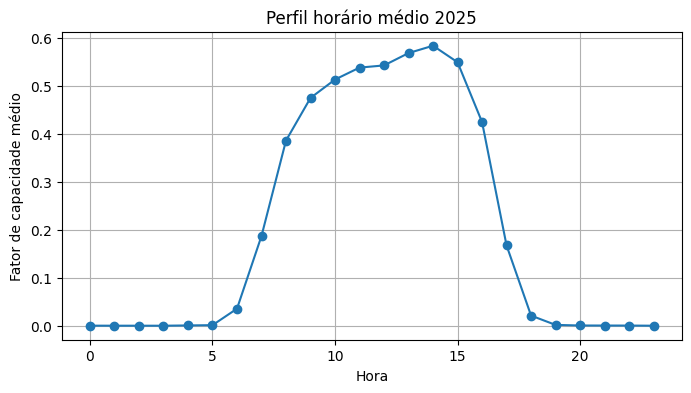

In [ ]:
plt.figure(figsize=(8,4))

perfil_diario_all.plot(marker='o')

plt.xlabel('Hora')
plt.ylabel('Fator de capacidade médio')
plt.title('Perfil horário médio 2025')

plt.grid()
plt.show()

In [ ]:
tabela_fc = (df_2025.groupby('time')['val_fatorcapacidade']
    .agg(
        Media='mean',
        Mediana='median',
        Desvio='std',
        N_registros='count'
    )
    .reset_index()
)

tabela_fc[['Media', 'Mediana', 'Desvio']] = (
    tabela_fc[['Media', 'Mediana', 'Desvio']]
    .round(3)
)

tabela_fc

,time,Media,Mediana,Desvio,N_registros
0,0,0.000,0.000,0.016,2190
1,1,0.000,0.000,0.013,2190
2,2,0.000,0.000,0.013,2190
3,3,0.000,0.000,0.011,2190
4,4,0.001,0.000,0.016,2190
5,5,0.002,0.000,0.016,2190
6,6,0.036,0.007,0.064,2190
7,7,0.187,0.129,0.180,2190
8,8,0.386,0.377,0.252,2190
9,9,0.475,0.513,0.281,2190


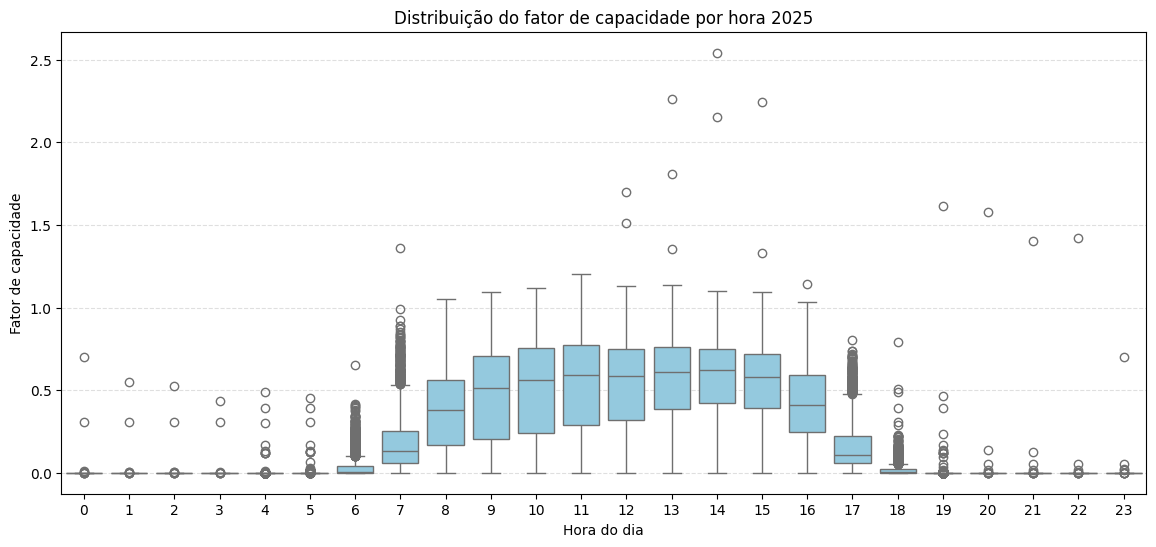

In [ ]:
plt.figure(figsize=(14,6))

sns.boxplot(data=df_2025, x='time', y='val_fatorcapacidade', color='skyblue', showfliers=True)

plt.title('Distribuição do fator de capacidade por hora 2025')
plt.xlabel('Hora do dia')
plt.ylabel('Fator de capacidade')

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.show()

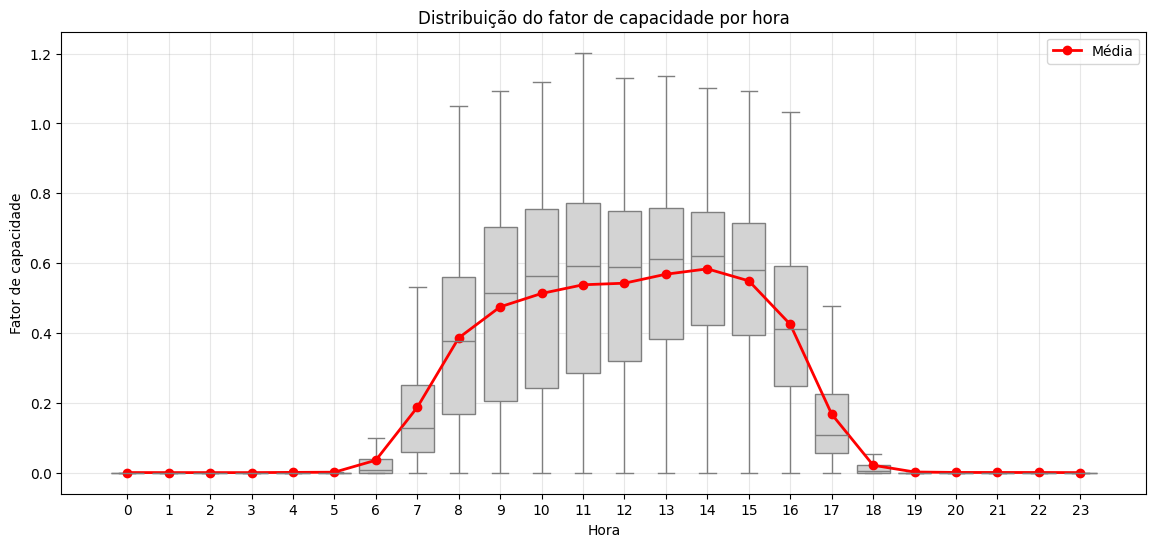

In [ ]:
plt.figure(figsize=(14,6))

sns.boxplot(data=df_2025, x='time', y='val_fatorcapacidade', showfliers=False, color='lightgray')

media = (df_2025.groupby('time')['val_fatorcapacidade'].mean())

plt.plot(range(24), media.values, color='red', marker='o', linewidth=2, label='Média')

plt.xlabel('Hora')
plt.ylabel('Fator de capacidade')
plt.title('Distribuição do fator de capacidade por hora')

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#fator de capacidade médio por hora
fc_hora = (df_2025.groupby('time')['val_fatorcapacidade'].mean().reset_index(name='FC_medio'))

In [ ]:
#percentual de contribuição
total_fc = fc_hora['FC_medio'].sum()
fc_hora['Percentual (%)'] = (fc_hora['FC_medio'] / total_fc * 100)
fc_hora['FC_medio'] = fc_hora['FC_medio'].round(3)
fc_hora['Percentual (%)'] = fc_hora['Percentual (%)'].round(2)

In [ ]:
fc_hora

,time,FC_medio,Percentual (%)
0,0,0.000,0.01
1,1,0.000,0.01
2,2,0.000,0.01
3,3,0.000,0.01
4,4,0.001,0.02
5,5,0.002,0.03
6,6,0.036,0.72
7,7,0.187,3.74
8,8,0.386,7.72
9,9,0.475,9.50


Como o fator de capacidade é uma variável adimensional, uma alternativa interessante é calcular a contribuição usando a geração verificada (val_geracaoverificada), pois ela representa a energia efetivamente produzida.

Mas comparando as duas tabelas é  possível ver que os valores não muda tanto assim, então posso seguir a analise com o Fator de Geração. E analisando esse fator de geração o horário entre 07-17 é mais interessante para analise.


In [ ]:
geracao_hora = (df_2025.groupby('time')['val_geracaoverificada'].mean().reset_index(name='Geracao_media'))

total = geracao_hora['Geracao_media'].sum()

geracao_hora['Percentual (%)'] = (geracao_hora['Geracao_media'] / total * 100)
geracao_hora

,time,Geracao_media,Percentual (%)
0,0,0.083366,0.008699
1,1,0.070301,0.007336
2,2,0.068474,0.007145
3,3,0.061039,0.006369
4,4,0.229897,0.023988
5,5,0.337209,0.035186
6,6,7.317904,0.763580
7,7,36.321768,3.789961
8,8,73.316068,7.650096
9,9,89.894512,9.379958


A partir da analise dos gráficos e tabelas, o horário das 07 ás 17 possui uma melhor representividade de dados diários.

O desvio padrão é maior entre 9h e 15h. Isso indica maior quantidade de variabilidade do clima nesses intervalo como, dias nublados, ensolarados, chuvas.

Em alguns horários a média é menor que a mediana, isso indica uma distribuição assimétrica. Provavelmente existem muitos dias excelentes de geração e alguns poucos dias muito ruins (nuvens fortes, chuva, etc.) que puxam a média para baixo

In [ ]:
df_2025 = df_2025[df_2025['time'].between(7, 17)]

In [ ]:
df_2025['time'].unique()

array([ 7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17], dtype=int32)

In [ ]:
df_2025.head()

,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,din_instante,val_geracaoprogramada,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade,date,time
42,-19.881624,-50.397030,-19.881624,-50.397030,Conj. Boa Hora,2025-01-01 07:00:00,43.0,68.260,178.3303,0.382773,2025-01-01,7
43,-20.790444,-51.529266,-20.790444,-51.529266,Conj. Castilho,2025-01-01 07:00:00,51.0,64.310,205.0400,0.313646,2025-01-01,7
44,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-01-01 07:00:00,15.5,20.398,81.0000,0.251827,2025-01-01,7
45,-21.893809,-49.863684,-21.855464,-49.838358,Conj. Guaimbê,2025-01-01 07:00:00,20.5,16.047,150.0400,0.106951,2025-01-01,7
46,-20.195849,-50.032683,-19.867222,-50.350000,Conj. Pedranópolis,2025-01-01 07:00:00,25.5,36.372,90.3600,0.402523,2025-01-01,7


In [ ]:
df_2025.to_csv("ONS_fcg_tratados_0717_2025.csv", index=False)

##### Separar por Usina


Verificar como está a representividade dos dados para cada uma das 06 usinas em São paulo

In [ ]:
df_2025.isna().sum()

,0
val_latitudesecoletora,0
val_longitudesecoletora,0
val_latitudepontoconexao,0
val_longitudepontoconexao,0
nom_usina_conjunto,0
din_instante,0
val_geracaoprogramada,165
val_geracaoverificada,0
val_capacidadeinstalada,0
val_fatorcapacidade,0


In [ ]:
df_2025.duplicated().sum()

np.int64(0)

In [ ]:
nom_usina_conjunto = df_2025['nom_usina_conjunto'].unique()
nom_usina_conjunto

array(['Conj. Boa Hora', 'Conj. Castilho', 'Conj. Dracena',
       'Conj. Guaimbê', 'Conj. Pedranópolis', 'Conj. Pereira Barreto'],
      dtype=object)

In [ ]:
import unicodedata
for usina in nom_usina_conjunto:
  df = df_2025[df_2025['nom_usina_conjunto']==usina]

  nome_limpo = unicodedata.normalize('NFKD', usina).encode('ASCII', 'ignore').decode('ASCII')
  nome_limpo = nome_limpo.replace('.', '').replace(' ', '_').lower()

  nome_arquivo = f"ONS_fcg_{nome_limpo}.csv"

  df.to_csv(nome_arquivo, index=False)

### Etapa 2 — Qualidade dos dados de geração (ONS)

*   Estatísticas descritivas do fator de capacidade.
*   Identificação de inconsistências (FC > 1).
*   Exclusão de Boa Hora e Guaimbê por apresentarem inconsistências físicas.




In [ ]:
def analisar_operacao_usina(df, nome_usina):
    df_usina = df[df['nom_usina_conjunto'] == nome_usina].copy()

    # Capacidade instalada (MW)
    capacidade = df_usina['val_capacidadeinstalada'].max()

    # Estatísticas do fator de capacidade
    fc_mode = df_usina['val_fatorcapacidade'].mode()
    fc_medio = df_usina['val_fatorcapacidade'].mean()
    fc_mediano = df_usina['val_fatorcapacidade'].median()
    fc_maximo = df_usina['val_fatorcapacidade'].max()
    fc_std = df_usina['val_fatorcapacidade'].std()

    # Coeficiente de variação (CV)
    if fc_medio != 0:
        cv = fc_std / fc_medio
    else:
        cv = None

    return pd.Series({
        'Usina': nome_usina,
        'Capacidade Instalada (MW)': round(capacidade, 2),
        'FC Médio': round(fc_medio, 4),
        'FC Mediano': round(fc_mediano, 4),
        'FC Máximo': round(fc_maximo, 4),
        'Desvio Padrão': round(fc_std, 4),
        'CV': round(cv, 4) if cv is not None else None
    })

In [ ]:
resultados = []

for usina in df_2025['nom_usina_conjunto'].unique():
    resultados.append(analisar_operacao_usina(df_2025, usina))

df_operacao = pd.DataFrame(resultados)

df_operacao

,Usina,Capacidade Instalada (MW),FC Médio,FC Mediano,FC Máximo,Desvio Padrão,CV
0,Conj. Boa Hora,178.33,0.4844,0.4859,1.1352,0.2945,0.6079
1,Conj. Castilho,205.04,0.4907,0.5152,0.9922,0.2912,0.5935
2,Conj. Dracena,81.00,0.4030,0.4174,0.8818,0.2610,0.6477
3,Conj. Guaimbê,150.04,0.3823,0.3539,2.5424,0.2626,0.6867
4,Conj. Pedranópolis,90.36,0.5115,0.5324,0.9737,0.2949,0.5766
5,Conj. Pereira Barreto,457.99,0.4203,0.4291,0.9834,0.2565,0.6104


###### Outliers

Conj. Guaimbê: 18 registros, com valores extremos (FC até 2,54)   
Conj. Boa Hora: 127 registros, mas com excesso menor (FC até 1,13)

In [ ]:
df_2025[df_2025['val_fatorcapacidade'] > 1][
    [
        'nom_usina_conjunto',
        'din_instante',
        'val_fatorcapacidade',
        'val_geracaoverificada',
        'val_capacidadeinstalada'
    ]
]

,nom_usina_conjunto,din_instante,val_fatorcapacidade,val_geracaoverificada,val_capacidadeinstalada
780,Conj. Boa Hora,2025-01-06 10:00:00,1.018212,181.578,178.3303
786,Conj. Boa Hora,2025-01-06 11:00:00,1.090634,194.493,178.3303
792,Conj. Boa Hora,2025-01-06 12:00:00,1.063975,189.739,178.3303
948,Conj. Boa Hora,2025-01-07 14:00:00,1.020387,181.966,178.3303
1068,Conj. Boa Hora,2025-01-08 10:00:00,1.003671,178.985,178.3303
...,...,...,...,...,...
47025,Conj. Guaimbê,2025-11-23 13:00:00,1.807365,271.177,150.0400
47031,Conj. Guaimbê,2025-11-23 14:00:00,1.090802,163.664,150.0400
47037,Conj. Guaimbê,2025-11-23 15:00:00,1.092742,163.955,150.0400
47892,Conj. Boa Hora,2025-11-29 14:00:00,1.033257,184.261,178.3303


In [ ]:
df_2025[
    df_2025['val_geracaoverificada'] >
    df_2025['val_capacidadeinstalada']
][
    [
        'nom_usina_conjunto',
        'din_instante',
        'val_geracaoverificada',
        'val_capacidadeinstalada',
        'val_fatorcapacidade'
    ]
].sort_values(
    'val_fatorcapacidade',
    ascending=False
)

,nom_usina_conjunto,din_instante,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade
24999,Conj. Guaimbê,2025-06-23 14:00:00,381.467,150.0400,2.542435
46881,Conj. Guaimbê,2025-11-22 13:00:00,339.688,150.0400,2.263983
25005,Conj. Guaimbê,2025-06-23 15:00:00,336.828,150.0400,2.244921
46887,Conj. Guaimbê,2025-11-22 14:00:00,323.262,150.0400,2.154505
47025,Conj. Guaimbê,2025-11-23 13:00:00,271.177,150.0400,1.807365
...,...,...,...,...,...
1068,Conj. Boa Hora,2025-01-08 10:00:00,178.985,178.3303,1.003671
2928,Conj. Boa Hora,2025-01-21 08:00:00,178.701,178.3303,1.002079
7290,Conj. Boa Hora,2025-02-20 15:00:00,178.583,178.3303,1.001417
3954,Conj. Boa Hora,2025-01-28 11:00:00,178.427,178.3303,1.000542


In [ ]:
df_2025.groupby(
    'nom_usina_conjunto'
)['val_capacidadeinstalada'].nunique()

,val_capacidadeinstalada
nom_usina_conjunto,
Conj. Boa Hora,1
Conj. Castilho,1
Conj. Dracena,1
Conj. Guaimbê,1
Conj. Pedranópolis,2
Conj. Pereira Barreto,2


In [ ]:
df_2025[
    df_2025['nom_usina_conjunto']=="Conj. Guaimbê"
]['val_capacidadeinstalada'].unique()

array([150.04])

In [ ]:
df_2025[
    df_2025['nom_usina_conjunto']=="Conj. Boa Hora"
]['val_capacidadeinstalada'].unique()

array([178.3303])

In [ ]:
df_2025['geracao_capacidade_ratio'] = (
    df_2025['val_geracaoverificada'] /
    df_2025['val_capacidadeinstalada']
)

In [ ]:
df_2025[
    df_2025['geracao_capacidade_ratio'] > 1
].groupby('nom_usina_conjunto').size()

,0
nom_usina_conjunto,
Conj. Boa Hora,127
Conj. Guaimbê,18


In [ ]:
df_outliers_fc = df_2025[
    df_2025['val_geracaoverificada'] >
    df_2025['val_capacidadeinstalada']
].copy()

df_outliers_fc[
    [
        'nom_usina_conjunto',
        'din_instante',
        'val_geracaoverificada',
        'val_capacidadeinstalada',
        'val_fatorcapacidade'
    ]
].sort_values(
    'val_fatorcapacidade',
    ascending=False
).head(30)

,nom_usina_conjunto,din_instante,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade
24999,Conj. Guaimbê,2025-06-23 14:00:00,381.467,150.0400,2.542435
46881,Conj. Guaimbê,2025-11-22 13:00:00,339.688,150.0400,2.263983
25005,Conj. Guaimbê,2025-06-23 15:00:00,336.828,150.0400,2.244921
46887,Conj. Guaimbê,2025-11-22 14:00:00,323.262,150.0400,2.154505
47025,Conj. Guaimbê,2025-11-23 13:00:00,271.177,150.0400,1.807365
46875,Conj. Guaimbê,2025-11-22 12:00:00,255.315,150.0400,1.701646
47019,Conj. Guaimbê,2025-11-23 12:00:00,226.966,150.0400,1.512703
24957,Conj. Guaimbê,2025-06-23 07:00:00,203.651,150.0400,1.357311
24993,Conj. Guaimbê,2025-06-23 13:00:00,203.605,150.0400,1.357005
46893,Conj. Guaimbê,2025-11-22 15:00:00,199.298,150.0400,1.328299


In [ ]:
df_outliers_fc['hora'] = df_outliers_fc['din_instante'].dt.hour

df_outliers_fc.groupby(
    ['nom_usina_conjunto','hora']
).size()

nom_usina_conjunto  hora
Conj. Boa Hora      8        2
                    9        5
                    10      19
                    11      27
                    12      24
                    13      21
                    14      15
                    15      13
                    16       1
Conj. Guaimbê       7        1
                    8        1
                    9        1
                    10       2
                    11       1
                    12       2
                    13       3
                    14       3
                    15       3
                    16       1
dtype: int64

In [ ]:
df_2025[['val_geracaoverificada',
         'val_capacidadeinstalada',
         'val_fatorcapacidade']].describe()

,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade
count,24090.000000,24090.000000,24090.000000
mean,85.909776,193.697891,0.448685
std,81.220651,126.022880,0.281519
min,0.000000,81.000000,0.000000
25%,28.531250,90.360000,0.189648
50%,61.400500,164.185150,0.450883
75%,118.899250,205.040000,0.685517
max,450.390000,457.994520,2.542435


In [ ]:
df_2025.groupby('nom_usina_conjunto').agg(
    capacidade=('val_capacidadeinstalada','max'),
    geracao_max=('val_geracaoverificada','max'),
    fc_max=('val_fatorcapacidade','max')
)

,capacidade,geracao_max,fc_max
nom_usina_conjunto,,,
Conj. Boa Hora,178.33030,202.443,1.135214
Conj. Castilho,205.04000,203.437,0.992182
Conj. Dracena,81.00000,71.426,0.881802
Conj. Guaimbê,150.04000,381.467,2.542435
Conj. Pedranópolis,90.36000,87.666,0.973678
Conj. Pereira Barreto,457.99452,450.390,0.983396


# Encontrar a Estação mais proxima de cada Conj. de Usinas

###  Etapa 3 — Associação espacial ONS × INMET


*   Cálculo da menor distância geodésica.
*   Definição da estação meteorológica mais representativa de cada conjunto.


In [ ]:
df_estacoes = pd.read_csv('/content/Catálogo de Estações Automáticas.csv')

In [ ]:
df_estacoes = df_estacoes[df_estacoes['UF']=='SP']

In [ ]:
df_estacoes = df_estacoes[df_estacoes['Nome'] != 'LINS']

In [ ]:
df_estacoes.head()

,Nome,UF,Situação,Latitude,Longitude,Altitude,Data de Instalação,Código
119,ARIRANHA,SP,Operante,-21.133056,-48.840556,"525,44",12/11/2007,A736
120,AVARE,SP,Operante,-23.101667,-48.941111,"776,36",21/09/2006,A725
121,BARRA BONITA,SP,Operante,-22.471111,-48.557500,"533,68",23/04/2008,A741
122,BARRA DO TURVO,SP,Operante,-24.962778,-48.416389,"659,89",02/07/2008,A746
123,BARRETOS,SP,Operante,-20.559167,-48.545000,"534,36",18/06/2010,A748


In [ ]:
df_estacoes['Latitude'] = (
    df_estacoes['Latitude']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

df_estacoes['Longitude'] = (
    df_estacoes['Longitude']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

In [ ]:
df_ons = (
    df_2025[
        ['id_ons',
         'nom_usina_conjunto',
         'val_latitudesecoletora',
         'val_longitudesecoletora']
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

In [ ]:
df_ons

,id_ons,nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora
0,CJU_SPUFBH,Conj. Boa Hora,-19.881624,-50.397030
1,CJU_SPCST3,Conj. Castilho,-20.790444,-51.529266
2,CJU_SPUFD,Conj. Dracena,-21.450214,-51.587776
3,CJU_SPCUFG,Conj. Guaimbê,-21.893809,-49.863684
4,CJU_SPPED,Conj. Pedranópolis,-20.195849,-50.032683
5,CJU_SPPB,Conj. Pereira Barreto,-20.620000,-51.300000


In [ ]:
df_ons_bt = df_ons.copy()

In [ ]:
df_inmet = (
    df_estacoes[
        ['Código',
         'Nome',
         'Latitude',
         'Longitude']
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

In [ ]:
df_inmet = df_inmet.dropna(subset=['Latitude', 'Longitude']).reset_index(drop=True)

In [ ]:
df_inmet.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 146 entries, 0 to 145
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Código     146 non-null    object 
 1   Nome       146 non-null    object 
 2   Latitude   146 non-null    float64
 3   Longitude  146 non-null    float64
dtypes: float64(2), object(2)
memory usage: 4.7+ KB


In [ ]:
df_inmet_bt = df_inmet.copy()

##### Distância Estações e Conj de Usinas

In [ ]:
from geopy.distance import geodesic

def mais_proxima(lat, lon, df_inmet):

    distancias = df_inmet.apply(
        lambda x: geodesic(
            (lat, lon),
            (x['Latitude'], x['Longitude'])
        ).km,
        axis=1
    )

    idx = distancias.idxmin()

    return pd.Series({
        'estacao': df_inmet.loc[idx, 'Nome'],
        'codigo': df_inmet.loc[idx, 'Código'],
        'distancia': distancias[idx]
    })

resultado = df_ons.apply(
    lambda x: mais_proxima(
        x['val_latitudesecoletora'],
        x['val_longitudesecoletora'],
        df_inmet
    ),
    axis=1
)

df_ons = pd.concat([df_ons, resultado], axis=1)

In [ ]:
df_ons

,id_ons,nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora,estacao,codigo,distancia
0,CJU_SPUFBH,Conj. Boa Hora,-19.881624,-50.397030,JALES,A733,37.592641
1,CJU_SPCST3,Conj. Castilho,-20.790444,-51.529266,DRACENA,A762,73.924809
2,CJU_SPUFD,Conj. Dracena,-21.450214,-51.587776,DRACENA,A762,3.779238
3,CJU_SPCUFG,Conj. Guaimbê,-21.893809,-49.863684,MARILIA,A763,39.230689
4,CJU_SPPED,Conj. Pedranópolis,-20.195849,-50.032683,JALES,A733,58.876604
5,CJU_SPPB,Conj. Pereira Barreto,-20.620000,-51.300000,VALPARAISO,A734,86.431677


##### Teste todas estações

In [ ]:
from geopy.distance import geodesic

def mais_proxima(lat, lon, df_inmet):

    distancias = df_inmet.apply(
        lambda x: geodesic(
            (lat, lon),
            (x['Latitude'], x['Longitude'])
        ).km,
        axis=1
    )

    idx = distancias.idxmin()

    return pd.Series({
        'estacao': df_inmet.loc[idx, 'Nome'],
        'codigo': df_inmet.loc[idx, 'Código'],
        'distancia': distancias[idx]
    })

resultado = df_ons.apply(
    lambda x: mais_proxima(
        x['val_latitudesecoletora'],
        x['val_longitudesecoletora'],
        df_inmet
    ),
    axis=1
)

df_ons = pd.concat([df_ons, resultado], axis=1)

In [ ]:
df_ons

,id_ons,nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora,estacao,codigo,distancia
0,CJU_SPUFBH,Conj. Boa Hora,-19.881624,-50.397030,JALES,A733,37.592641
1,CJU_SPCST3,Conj. Castilho,-20.790444,-51.529266,DRACENA,A762,73.924809
2,CJU_SPUFD,Conj. Dracena,-21.450214,-51.587776,DRACENA,A762,3.779238
3,CJU_SPCUFG,Conj. Guaimbê,-21.893809,-49.863684,LINS,A727,28.522777
4,CJU_SPPED,Conj. Pedranópolis,-20.195849,-50.032683,JALES,A733,58.876604
5,CJU_SPPB,Conj. Pereira Barreto,-20.620000,-51.300000,VALPARAISO,A734,86.431677


###### Teste usinas localizas a um raio de 100km dos conj de usinas

\exploratory\teste_usinas_inmet_100km.ipynb

# Dados Estações Automáticas INMET

### Etapa 5 — Qualidade dos dados do INMET

exploratory\EXP_03_meteorological_data_quality.ipynb.ipynb

# Verificar a consistencia dos dados por usina

In [ ]:
df_2025 = pd.read_csv('/content/ONS_fcg_tratados_0717_2025.csv')
df_2025

,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,din_instante,val_geracaoprogramada,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade,date,time
0,-19.881624,-50.397030,-19.881624,-50.397030,Conj. Boa Hora,2025-01-01 07:00:00,43.0,68.260,178.33030,0.382773,2025-01-01,7
1,-20.790444,-51.529266,-20.790444,-51.529266,Conj. Castilho,2025-01-01 07:00:00,51.0,64.310,205.04000,0.313646,2025-01-01,7
2,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-01-01 07:00:00,15.5,20.398,81.00000,0.251827,2025-01-01,7
3,-21.893809,-49.863684,-21.855464,-49.838358,Conj. Guaimbê,2025-01-01 07:00:00,20.5,16.047,150.04000,0.106951,2025-01-01,7
4,-20.195849,-50.032683,-19.867222,-50.350000,Conj. Pedranópolis,2025-01-01 07:00:00,25.5,36.372,90.36000,0.402523,2025-01-01,7
...,...,...,...,...,...,...,...,...,...,...,...,...
24085,-20.790444,-51.529266,-20.790444,-51.529266,Conj. Castilho,2025-12-31 17:00:00,70.5,10.077,205.04000,0.049147,2025-12-31,17
24086,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-12-31 17:00:00,22.5,16.616,81.00000,0.205136,2025-12-31,17
24087,-21.893809,-49.863684,-21.855464,-49.838358,Conj. Guaimbê,2025-12-31 17:00:00,24.5,31.433,150.04000,0.209497,2025-12-31,17
24088,-20.195849,-50.032683,-20.195849,-50.032683,Conj. Pedranópolis,2025-12-31 17:00:00,27.5,6.116,90.00000,0.067956,2025-12-31,17


In [ ]:
nom_usina_conjunto = ['Conj. Castilho', 'Conj. Dracena', 'Conj. Pedranópolis', 'Conj. Pereira Barreto']

In [ ]:
estatisticas = (
    df_2025
    .groupby('nom_usina_conjunto')
    ['val_fatorcapacidade']
    .agg(
        media='mean',
        desvio='std',
        minimo='min',
        maximo='max'
    )
)

estatisticas

,media,desvio,minimo,maximo
nom_usina_conjunto,,,,
Conj. Boa Hora,0.484385,0.294471,0.000000,1.135214
Conj. Castilho,0.490688,0.291212,0.000000,0.992182
Conj. Dracena,0.402956,0.260976,0.000000,0.881802
Conj. Guaimbê,0.382335,0.262552,0.000000,2.542435
Conj. Pedranópolis,0.511462,0.294901,0.000022,0.973678
Conj. Pereira Barreto,0.420285,0.256528,0.000000,0.983396


In [ ]:
df_2025['din_instante'] = pd.to_datetime(df_2025['din_instante'])
df_2025['din_instante'].dtype

dtype('<M8[ns]')

In [ ]:
df_dracena = df_2025[df_2025['nom_usina_conjunto']=='Conj. Dracena'].copy()

In [ ]:
df_dracena.head(3)

,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,din_instante,val_geracaoprogramada,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade,date,time
2,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-01-01 07:00:00,15.5,20.398,81.0,0.251827,2025-01-01,7
8,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-01-01 08:00:00,17.0,16.746,81.0,0.206741,2025-01-01,8
14,-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,2025-01-01 09:00:00,16.5,19.383,81.0,0.239296,2025-01-01,9


In [ ]:
df_dracena.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4015 entries, 2 to 24086
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   val_latitudesecoletora     4015 non-null   float64       
 1   val_longitudesecoletora    4015 non-null   float64       
 2   val_latitudepontoconexao   4015 non-null   float64       
 3   val_longitudepontoconexao  4015 non-null   float64       
 4   nom_usina_conjunto         4015 non-null   object        
 5   din_instante               4015 non-null   datetime64[ns]
 6   val_geracaoprogramada      4004 non-null   float64       
 7   val_geracaoverificada      4015 non-null   float64       
 8   val_capacidadeinstalada    4015 non-null   float64       
 9   val_fatorcapacidade        4015 non-null   float64       
 10  date                       4015 non-null   object        
 11  time                       4015 non-null   int64         
dtypes: datetim

# Unido os dados ONS + INMET  


Verificar consistencia dos dados do INMET, data de criação da estação se estar em operação.

In [ ]:
df_2025.head()

,cod_pontoconexao,nom_pontoconexao,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,id_ons,din_instante,val_geracaoprogramada,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade,date,time
0,SPUFBH138-A,COL BOA HORA138kVA,-19.881624,-50.397030,-19.881624,-50.397030,Conj. Boa Hora,CJU_SPUFBH,2025-01-01 00:00:00,0.0,0.0,178.3303,0.0,2025-01-01,00:00:00
1,SPCST3138-A,CASTILHO 03138kVA,-20.790444,-51.529266,-20.790444,-51.529266,Conj. Castilho,CJU_SPCST3,2025-01-01 00:00:00,0.0,0.0,205.0400,0.0,2025-01-01,00:00:00
2,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 00:00:00,0.0,0.0,81.0000,0.0,2025-01-01,00:00:00
3,SPGET-138-A,GETULINA - 138 kV (A),-21.893809,-49.863684,-21.855464,-49.838358,Conj. Guaimbê,CJU_SPCUFG,2025-01-01 00:00:00,0.0,0.0,150.0400,0.0,2025-01-01,00:00:00
4,SPAGV-138,AGUA VERMELHA - 138 kV (A),-20.195849,-50.032683,-19.867222,-50.350000,Conj. Pedranópolis,CJU_SPPED,2025-01-01 00:00:00,0.0,0.0,90.3600,0.0,2025-01-01,00:00:00


In [ ]:
df_ons

,id_ons,nom_usina_conjunto,val_latitudesecoletora,val_longitudesecoletora,estacao,codigo,distancia
0,CJU_SPUFBH,Conj. Boa Hora,-19.881624,-50.397030,JALES,A733,37.592641
1,CJU_SPCST3,Conj. Castilho,-20.790444,-51.529266,DRACENA,A762,73.924809
2,CJU_SPUFD,Conj. Dracena,-21.450214,-51.587776,DRACENA,A762,3.779238
3,CJU_SPCUFG,Conj. Guaimbê,-21.893809,-49.863684,MARILIA,A763,39.230689
4,CJU_SPPED,Conj. Pedranópolis,-20.195849,-50.032683,JALES,A733,58.876604
5,CJU_SPPB,Conj. Pereira Barreto,-20.620000,-51.300000,VALPARAISO,A734,86.431677


In [ ]:
def extract_normalize_stations(estacao):
    path = f"/content/dados_{estacao}_H_2025-01-01_2025-12-31.csv"

    df = pd.read_csv(path, sep=";", skiprows=9)
    df['Hora Medicao'] = df['Hora Medicao'].astype(str).str.zfill(4)

    # Cria o formato de hora padrão (HH:MM:SS)
    df['time'] = df['Hora Medicao'].str[:2] + ":00:00"
    df = df.rename(columns={"Data Medicao": "date"})

    # 3. Junta as colunas de texto 'date' e 'time' em uma coluna única do tipo Datetime (Ainda em UTC)
    df['data_hora_utc'] = pd.to_datetime(df['date'] + ' ' + df['time'], format='%Y-%m-%d %H:%M:%S')

    # 4. Ajuste de Engenharia de Dados: Converte UTC para UTC-3 (Subtrai 3 horas)
    # Criamos a coluna 'din_instante' com o mesmo nome que o ONS usa para facilitar o merge depois
    df['datetime'] = df['data_hora_utc'] - pd.Timedelta(hours=3)

    # 5. Organiza o DataFrame: descarta as colunas intermediárias de texto que não usaremos mais
    df = df.drop(columns=['date', 'time', 'data_hora_utc', 'Hora Medicao', 'Unnamed: 22'])

    return df

"Todas as informações divulgadas pelo Instituto estão em horário UTC, para a conversão com o horário oficial de Brasília, é necessário subtrair 3 horas."


Os dados das estações automáticas são brutos e não passam por um processo de consistência (validação).


Possíveis falhas decorrentes de problemas (pane) nos sensores, comunicação nas estações ou ausência de observações estão identificadas pelo número "9999", o termo "Null" ou estarão em branco. Os dados que não estão disponíveis no portal do Inmet (consulta dados) são inexistentes.

### A762 Dracena

In [ ]:
df_A762 = extract_normalize_stations('A762')

In [ ]:
df_A762.head()

,"PRECIPITACAO TOTAL, HORARIO(mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)","PRESSAO ATMOSFERICA REDUZIDA NIVEL DO MAR, AUT(mB)",PRESSAO ATMOSFERICA MAX.NA HORA ANT. (AUT)(mB),PRESSAO ATMOSFERICA MIN. NA HORA ANT. (AUT)(mB),RADIACAO GLOBAL(Kj/m²),TEMPERATURA DA CPU DA ESTACAO(°C),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA DO PONTO DE ORVALHO(°C),TEMPERATURA MAXIMA NA HORA ANT. (AUT)(°C),...,TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT)(°C),TENSAO DA BATERIA DA ESTACAO(V),UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, DIRECAO HORARIA (gr)(° (gr))","VENTO, RAJADA MAXIMA(m/s)","VENTO, VELOCIDADE HORARIA(m/s)",datetime
0,0,"965,1","1008,4","965,4","965,1","-3,6",29.0,"26,2","20,2","27,5",...,"21,6","20,1","12,5",73.0,66.0,69.0,86.0,"5,3","1,7",2024-12-31 21:00:00
1,0,"965,7","1009,2","965,7","965,1","-3,6",28.0,"25,1","19,5","26,2",...,"20,3","19,1","12,5",71.0,66.0,71.0,79.0,"3,3","2,3",2024-12-31 22:00:00
2,0,"966,4","1009,9","966,4","965,7","-3,6",27.0,"25,2","19,4","25,4",...,"19,6","19,2","12,5",72.0,69.0,70.0,113.0,"3,3","1,7",2024-12-31 23:00:00
3,0,"966,4","1009,9","966,6","966,3","-3,6",26.0,"25,2","19,6","25,4",...,"19,8","19,4","12,4",75.0,70.0,71.0,126.0,"3,1","1,8",2025-01-01 00:00:00
4,0,"966,1","1009,7","966,4","966,1","-3,6",26.0,"24,4","20,2","25,2",...,"20,3","19,6","12,4",78.0,71.0,78.0,91.0,"3,1","1,5",2025-01-01 01:00:00


In [ ]:
df_dracena = df_dracena.drop(columns=['cod_pontoconexao', 'nom_pontoconexao', 'val_latitudesecoletora', 'val_longitudesecoletora', 'val_latitudepontoconexao', 'val_longitudepontoconexao', 'nom_usina_conjunto', 'id_ons', 'val_geracaoprogramada', 'hora', 'din_instante'])

In [ ]:
df_dracena.info()

<class 'pandas.core.frame.DataFrame'>
Index: 8760 entries, 2 to 52556
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   din_instante             8760 non-null   datetime64[ns]
 1   val_geracaoverificada    8760 non-null   float64       
 2   val_capacidadeinstalada  8760 non-null   float64       
 3   val_fatorcapacidade      8760 non-null   float64       
 4   date                     8760 non-null   object        
 5   time                     8760 non-null   object        
 6   datetime                 8760 non-null   datetime64[ns]
 7   hora                     8760 non-null   int32         
dtypes: datetime64[ns](2), float64(3), int32(1), object(2)
memory usage: 839.8+ KB


In [ ]:
df_dracena['datetime']

,datetime
2,2025-01-01 00:00:00
8,2025-01-01 01:00:00
14,2025-01-01 02:00:00
20,2025-01-01 03:00:00
26,2025-01-01 04:00:00
...,...
52532,2025-12-31 19:00:00
52538,2025-12-31 20:00:00
52544,2025-12-31 21:00:00
52550,2025-12-31 22:00:00


In [ ]:
df_dracena.head(1)

,din_instante,val_geracaoverificada,val_capacidadeinstalada,val_fatorcapacidade,date,time,datetime,hora
2,2025-01-01,0.0,81.0,0.0,2025-01-01,00:00:00,2025-01-01,0


In [ ]:
# Como as duas tabelas agora têm a coluna 'din_instante' idêntica e no mesmo fuso:
df_dracena_merge = pd.merge(df_dracena, df_A762, on='datetime', how='inner')

In [ ]:
df_dracena_merge.head()

,cod_pontoconexao,nom_pontoconexao,val_latitudesecoletora,val_longitudesecoletora,val_latitudepontoconexao,val_longitudepontoconexao,nom_usina_conjunto,id_ons,din_instante,val_geracaoprogramada,...,TEMPERATURA MINIMA NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT)(°C),TENSAO DA BATERIA DA ESTACAO(V),UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, DIRECAO HORARIA (gr)(° (gr))","VENTO, RAJADA MAXIMA(m/s)","VENTO, VELOCIDADE HORARIA(m/s)"
0,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 00:00:00,0.0,...,"24,4","19,8","19,4","12,4",75.0,70.0,71.0,126.0,"3,1","1,8"
1,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 01:00:00,0.0,...,"24,4","20,3","19,6","12,4",78.0,71.0,78.0,91.0,"3,1","1,5"
2,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 02:00:00,0.0,...,"24,1","20,7","20,1","12,4",81.0,76.0,77.0,86.0,"4,6",3
3,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 03:00:00,0.0,...,"24,1","21,9","20,7","12,4",88.0,77.0,88.0,89.0,"5,2","2,4"
4,SPDRA-138,DRACENA - 138 kV (A),-21.450214,-51.587776,-21.457222,-51.526667,Conj. Dracena,CJU_SPUFD,2025-01-01 04:00:00,0.0,...,"23,3","23,7",22,"12,4",100.0,88.0,100.0,82.0,"3,5","1,6"


Ok, para a seleção de usinas no estudo eu tenho que verificar o Constrained off para que o modelo entenda que em certo dia foi gerado energia, mas por motivos operacionais a geração foi cortada.



In [ ]:
url_all = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/restricao_coff_fotovoltaica_tm/RESTRICAO_COFF_FOTOVOLTAICA_2025_12.csv"

In [ ]:
url_co = "https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/restricao_coff_fotovoltaica_detail_tm/RESTRICAO_COFF_FOTOVOLTAICA_DETAIL_2025_12.csv"

In [ ]:
months = ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
data_co = []

for month in months:
  url_co = f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/restricao_coff_fotovoltaica_tm/RESTRICAO_COFF_FOTOVOLTAICA_2025_{month}.csv"
  df_co = pd.read_csv(url_co, sep=';')

  data_co.append(df_co)

dfco_2025 = pd.concat(data_co, ignore_index=True)

In [ ]:
dfco_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1161120 entries, 0 to 1161119
Data columns (total 16 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   id_subsistema               1161120 non-null  object 
 1   nom_subsistema              1161120 non-null  object 
 2   id_estado                   1161120 non-null  object 
 3   nom_estado                  1161120 non-null  object 
 4   nom_usina                   1161120 non-null  object 
 5   id_ons                      1161120 non-null  object 
 6   ceg                         1161120 non-null  object 
 7   din_instante                1161120 non-null  object 
 8   val_geracao                 1161120 non-null  float64
 9   val_geracaolimitada         310559 non-null   float64
 10  val_disponibilidade         1161120 non-null  float64
 11  val_geracaoreferencia       1161120 non-null  float64
 12  val_geracaoreferenciafinal  26275 non-null    float64
 1

In [ ]:
dfco_2025.to_csv("ONS_coo_2025.csv", index=False)